# Jev vs. Claude: Benchmarking AI on software requirement classification

**Why this experiment:** As a Product Manager working on healthcare data quality, I deal with classification and data labeling tasks where decisions need to be made accurately and at scale. I wanted to explore whether a purpose-built decision model like Jev could be a faster, cheaper alternative to a general-purpose LLM for these tasks.

Jev (TypeSafe AI) claims to be up to 193x faster and 444x cheaper than general-purpose LLMs on decision tasks. I tested these claims against Claude using a straightforward classification problem: labeling software requirements as **functional** (what the system does) or **non-functional** (how well it does it).

**Models compared**
- **Jev:** Decision model that returns a fixed classification and confidence score, without an explanation.
- **Claude:** General-purpose LLM that returns the same classification with a one-line rationale.

Both received identical definitions and neither was trained on the evaluation data.

**Dataset:** human-labeled software requirements from [`limsc/fr-nfr-classification`](https://huggingface.co/datasets/limsc/fr-nfr-classification) on Hugging Face, plus a small set of messy requirements:
- **Development (143, Hugging Face validation split):** Used to refine prompts and select the review threshold.
- **Test (144, Hugging Face test split):** Held out and used only for the final evaluation.
- **Messy (36, `data/messy_requirements.csv`):** Multi-sentence requirements with typos, jargon and less structured wording.

**Evaluation:** Accuracy, processing speed, cost at volume, consistency across repeated runs, and automation potential (what can be classified automatically versus routed for human review).

**Limitations:** The Hugging Face dataset is undocumented and appears to derive from the public PROMISE benchmark, which both models may have seen during training. The messy set was generated with Claude's assistance, which could bias those results in Claude's favor. Findings apply only to these two configurations and this classification task.

## 1. Setup

In [1]:
%pip install -q typesafe-sdk anthropic pandas matplotlib datasets

**How to run this in two stages**
1. `STAGE = "tune"` runs the dev set once. Read the mistakes, reword the definitions below, and rerun as often as you like.
2. `STAGE = "final"` runs dev, test and messy, 3 times each. Don't change the wording after this. If you do, the test set has effectively become a second dev set.

Results are cached in `RESULTS_PATH`, so rerunning only calls the APIs for missing or failed rows.

In [2]:
import os

STAGE = "tune"                     # "tune" or "final"
MESSY_PATH = "data/messy_requirements.csv"
CLAUDE_MODEL = "claude-opus-5-5"   # or "claude-haiku-5-5" for the fastest, cheapest Claude
LIMIT = 10                         # max requirements per set, for cheap trial runs. None = all
RETRY_FAILED = True                # on rerun, retry calls that failed

TARGET_ACCURACY = 0.95             # human-review check: automate only what's at least this accurate on dev
MONTHLY_VOLUME = 10_000            # requirements per month, for the cost estimate

SPLITS = ["dev"] if STAGE == "tune" else ["dev", "test", "messy"]
REPEATS = 1 if STAGE == "tune" else 3
RESULTS_PATH = f"results/results_{CLAUDE_MODEL}.csv"
os.makedirs("results", exist_ok=True)

DATASET = "limsc/fr-nfr-classification"
LABELS = ["functional", "non_functional"]
HUMAN_LABEL = {1: "functional", 0: "non_functional"}

# Identical definitions for both models. Tune these on dev only.
FUNCTIONAL = ("Describes something the system does: a feature, behavior, input, "
              "output, or action a user can take")
NON_FUNCTIONAL = ("Describes how well the system does things: performance, security, "
                  "usability, reliability, look and feel, legal, or other quality constraints")

# USD per million tokens, from third-party reports (Oct 2026). Verify before publishing.
# Set a model's entry to None to show N/A.
PRICES_PER_MTOK = {
    "Jev": {"input": 0.042, "output": 0.0},
    "claude-haiku-5-5": {"input": 0.10, "output": 0.50},
    "claude-opus-5-5": {"input": 4.00, "output": 20.00},
}

**Load the requirements and any saved results.**

In [3]:
import os
import pandas as pd

from datasets import load_dataset

hf = load_dataset(DATASET)  # downloads once, then cached on your machine
dev_name = next(n for n in ["validation", "val", "valid"] if n in hf)  # the dataset's name for its validation split

def from_hf(split_name, label, offset):
    d = hf[split_name]
    return pd.DataFrame({"row": [offset + i for i in range(len(d))], "split": label,
                         "requirement": d["reqs"],
                         "human_label": [HUMAN_LABEL[v] for v in d["is_functional"]]})

messy = pd.read_csv(MESSY_PATH)
messy_items = pd.DataFrame({"row": 30000 + messy.id, "split": "messy",
                            "requirement": messy.requirement, "human_label": messy.label})

# Row ids are offset per set (dev 10000+, test 20000+, messy 30000+) so they never collide in the results file
items = pd.concat([from_hf(dev_name, "dev", 10000), from_hf("test", "test", 20000), messy_items])
items = items[items.split.isin(SPLITS)]

if LIMIT:  # sample evenly within each set so a quick run stays representative
    items = pd.concat([g.sample(n=min(LIMIT, len(g)), random_state=0) for _, g in items.groupby("split")])
items = items.sort_values("row").reset_index(drop=True)

# One row per (requirement, run): the same requirement is asked REPEATS times
base = items.merge(pd.DataFrame({"run": range(1, REPEATS + 1)}), how="cross")

RESULT_COLS = [
    "jev_status", "jev_label", "jev_confidence", "jev_ms", "jev_in_tokens", "jev_out_tokens", "jev_error",
    "claude_model", "claude_status", "claude_label", "claude_reason", "claude_ms",
    "claude_in_tokens", "claude_out_tokens", "claude_error",
]

if os.path.exists(RESULTS_PATH):
    saved = pd.read_csv(RESULTS_PATH)
    df = base.merge(saved[["row", "run"] + [c for c in RESULT_COLS if c in saved.columns]],
                    on=["row", "run"], how="left")
    selected = set(zip(base.row, base.run))
    extra = saved[[k not in selected for k in zip(saved.row, saved.run)]]  # kept, never overwritten
else:
    df, extra = base.copy(), pd.DataFrame()

for c in RESULT_COLS:
    if c not in df.columns:
        df[c] = None
df = df.astype({c: "object" for c in RESULT_COLS})

def needs_jev(r):
    return r.jev_status != "ok" and (RETRY_FAILED or pd.isna(r.jev_status))

def needs_claude(r):
    if r.claude_status == "ok" and r.claude_model == CLAUDE_MODEL:
        return False
    return RETRY_FAILED or pd.isna(r.claude_status) or r.claude_model != CLAUDE_MODEL

todo_jev = sum(needs_jev(r) for r in df.itertuples())
todo_claude = sum(needs_claude(r) for r in df.itertuples())
print(f"Stage: {STAGE} | sets: {', '.join(f'{s} ({n})' for s, n in items.split.value_counts().reindex(SPLITS).items())}"
      f" | {REPEATS} run(s) each")
print(f"API calls still needed: Jev {todo_jev}, Claude {todo_claude}")

Stage: tune | sets: dev (10) | 1 run(s) each
API calls still needed: Jev 0, Claude 0


**API keys.** Asked for only if API calls are needed. They stay in memory and are never printed or saved.

In [4]:
from getpass import getpass

if todo_jev and not os.environ.get("TYPESAFE_API_KEY"):
    os.environ["TYPESAFE_API_KEY"] = getpass("TypeSafe API key (console.typesafe.ai/keys): ")
if todo_claude and not os.environ.get("ANTHROPIC_API_KEY"):
    os.environ["ANTHROPIC_API_KEY"] = getpass("Anthropic API key (console.anthropic.com): ")

## 2. Run the evaluation

Each requirement goes to both models, once per run. A failed call is saved with its error, never dropped silently.

In [5]:
import time

def ask_jev(client, text):
    from typesafe_sdk import Choice
    questions = {
        "type": Choice(
            instructions="Is `requirement` a functional or a non-functional software requirement?",
            criteria={"functional": FUNCTIONAL, "non_functional": NON_FUNCTIONAL},
        ),
    }
    start = time.perf_counter()
    r = client.system_one(state={"requirement": text}, questions=questions)
    ms = (time.perf_counter() - start) * 1000
    ans = r.choices["type"]
    return {"jev_label": ans.choice, "jev_confidence": round(ans.confidence, 3), "jev_ms": round(ms),
            "jev_in_tokens": r.usage.input_tokens or 0, "jev_out_tokens": r.usage.output_tokens or 0}


CLAUDE_SYSTEM = (
    "You classify software requirements.\n"
    f"functional: {FUNCTIONAL}.\n"
    f"non_functional: {NON_FUNCTIONAL}."
)
CLAUDE_TOOL = {
    "name": "classify_requirement",
    "description": "Record whether the requirement is functional or non-functional.",
    "input_schema": {
        "type": "object",
        "properties": {
            "label": {"type": "string", "enum": LABELS},
            "reason": {"type": "string", "description": "One short sentence explaining the choice."},
        },
        "required": ["label", "reason"],
    },
}

def ask_claude(client, text):
    # Default sampling settings, as most teams would call it. The stability check measures the effect.
    start = time.perf_counter()
    msg = client.messages.create(
        model=CLAUDE_MODEL,
        max_tokens=1024,  # room for the model to reason before answering
        system=CLAUDE_SYSTEM + "\nAlways answer by calling the classify_requirement tool.",
        tools=[CLAUDE_TOOL],
        tool_choice={"type": "auto"},  # forced tool use ("tool"/"any") isn't supported by this model
        messages=[{"role": "user", "content": f"Requirement: {text}"}],
    )
    ms = (time.perf_counter() - start) * 1000
    call = next((b for b in msg.content if b.type == "tool_use"), None)
    if call is None:  # count a plain-text reply as a failed call, not a guessed label
        raise ValueError("Claude answered without calling the tool")
    return {"claude_label": call.input["label"], "claude_reason": call.input.get("reason", ""),
            "claude_ms": round(ms), "claude_in_tokens": msg.usage.input_tokens,
            "claude_out_tokens": msg.usage.output_tokens}


def save():
    out = pd.concat([df, extra], ignore_index=True) if len(extra) else df
    out.sort_values(["row", "run"]).to_csv(RESULTS_PATH, index=False)

def short_error(e):
    return f"{type(e).__name__}: {str(e)[:200]}"


if todo_jev or todo_claude:
    jev_client = claude_client = None
    if todo_jev:
        from typesafe_sdk import TypeSafeClient
        jev_client = TypeSafeClient()
    if todo_claude:
        import anthropic
        claude_client = anthropic.Anthropic()

    for n, i in enumerate(df.index, 1):
        r = df.loc[i]
        if needs_jev(r):
            try:
                for k, v in ask_jev(jev_client, r.requirement).items():
                    df.at[i, k] = v
                df.at[i, "jev_status"], df.at[i, "jev_error"] = "ok", None
            except Exception as e:
                df.at[i, "jev_status"], df.at[i, "jev_error"] = "error", short_error(e)
        if needs_claude(r):
            df.at[i, "claude_model"] = CLAUDE_MODEL
            try:
                for k, v in ask_claude(claude_client, r.requirement).items():
                    df.at[i, k] = v
                df.at[i, "claude_status"], df.at[i, "claude_error"] = "ok", None
            except Exception as e:
                df.at[i, "claude_status"], df.at[i, "claude_error"] = "error", short_error(e)
        if n % 10 == 0:
            save()  # checkpoint: an interruption loses at most 10 rows
        print(f"\r{n}/{len(df)} calls", end="")
    save()
    if jev_client is not None:
        jev_client.close()
    print(f"\nSaved to {RESULTS_PATH}")
else:
    print(f"All {len(df)} calls already have results. No API calls made.")

All 10 calls already have results. No API calls made.


## 3. Model comparison

Everything from here reads only the saved CSV, so it reruns without any API calls. Headline numbers use the **first run** on the **test** set (or dev, during tuning).

In [6]:
import math
import numpy as np

res = base[["row", "run"]].merge(pd.read_csv(RESULTS_PATH), on=["row", "run"], how="left")
for col in ["split", "requirement", "human_label"]:
    if col in base.columns:
        res[col] = base[col].values  # labels always come from the dataset, not the cache

jev_ok = res.jev_status == "ok"
claude_ok = (res.claude_status == "ok") & (res.claude_model == CLAUDE_MODEL)
ev_all = res[jev_ok & claude_ok].copy()
ev_all["jev_correct"] = ev_all.jev_label == ev_all.human_label
ev_all["claude_correct"] = ev_all.claude_label == ev_all.human_label
ev_all["models_agree"] = ev_all.jev_label == ev_all.claude_label

HEADLINE = "test" if "test" in SPLITS else SPLITS[0]
ev = ev_all[(ev_all.split == HEADLINE) & (ev_all.run == 1)].copy()
N = len(ev)

print(f"Headline set: {HEADLINE}, run 1 | {N} requirements answered by both models")
print(f"Calls: {len(res)} per model | failed or missing: Jev {int((~jev_ok).sum())}, "
      f"Claude {int((~claude_ok).sum())} (excluded from every metric below)")
if STAGE == "tune":
    print("Tuning stage: these are dev numbers, for adjusting wording only. Don't report them.")
if (~jev_ok).any() or (~claude_ok).any():
    display(pd.concat([
        res[~jev_ok].assign(model="Jev", error=lambda t: t.jev_error),
        res[~claude_ok].assign(model="Claude", error=lambda t: t.claude_error),
    ])[["row", "run", "split", "model", "error"]].head(20))

Headline set: dev, run 1 | 10 requirements answered by both models
Calls: 10 per model | failed or missing: Jev 0, Claude 0 (excluded from every metric below)
Tuning stage: these are dev numbers, for adjusting wording only. Don't report them.


In [7]:
def cost_per_1000(model_key, in_col, out_col):
    price = PRICES_PER_MTOK.get(model_key)
    if not price or price.get("input") is None or price.get("output") is None or not len(ev_all):
        return None
    per_call = (ev_all[in_col].mean() * price["input"] + ev_all[out_col].mean() * price["output"]) / 1e6
    return per_call * 1000

def money(x, digits=2):
    return "N/A" if x is None else f"${x:,.{digits}f}"

def model_row(name, prefix, price_key, ok_mask):
    c1k = cost_per_1000(price_key, f"{prefix}_in_tokens", f"{prefix}_out_tokens")
    ms = ev_all[f"{prefix}_ms"].astype(float)
    return {"Model": name,
            "Correct": f"{int(ev[f'{prefix}_correct'].sum())} / {N}",
            "Accuracy": f"{ev[f'{prefix}_correct'].mean():.1%}",
            "Median time": f"{ms.median():,.0f} ms",
            "Slowest 5% (p95)": f"{ms.quantile(0.95):,.0f} ms",
            "Failed calls": f"{(~ok_mask).mean():.1%}",
            "Cost per 1,000": money(c1k, 4),
            f"Cost per month ({MONTHLY_VOLUME:,})": money(None if c1k is None else c1k * MONTHLY_VOLUME / 1000)}

scorecard = pd.DataFrame([
    model_row("Jev", "jev", "Jev", jev_ok),
    model_row(f"Claude ({CLAUDE_MODEL})", "claude", CLAUDE_MODEL, claude_ok),
]).set_index("Model")
print(f"Accuracy: {HEADLINE} set, run 1, n = {N}. Time, failures and cost: every call in this run. "
      "Prices are third-party reported; verify before publishing.")
scorecard

Accuracy: dev set, run 1, n = 10. Time, failures and cost: every call in this run. Prices are third-party reported; verify before publishing.


,Correct,Accuracy,Median time,Slowest 5% (p95),Failed calls,"Cost per 1,000","Cost per month (10,000)"
Model,,,,,,,
Jev,8 / 10,80.0%,51 ms,87 ms,0.0%,$0.0165,$0.16
Claude (claude-opus-5-5),8 / 10,80.0%,"1,926 ms","2,715 ms",0.0%,$4.9036,$49.04


**Correct vs. incorrect, side by side**

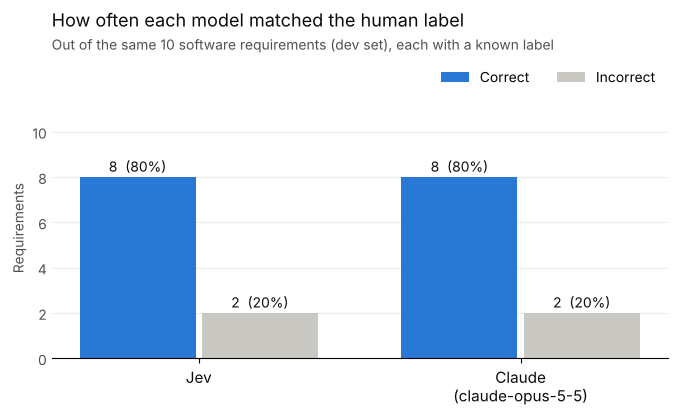

In [8]:
import matplotlib.pyplot as plt

CORRECT, INCORRECT = "#2a78d6", "#c9c8c2"
TEXT, MUTED = "#0b0b0b", "#52514e"

models = ["Jev", f"Claude\n({CLAUDE_MODEL})"]
correct = [int(ev.jev_correct.sum()), int(ev.claude_correct.sum())]
incorrect = [N - c for c in correct]

fig, ax = plt.subplots(figsize=(7, 4.2))
x = range(len(models))
w = 0.36
bars_c = ax.bar([i - w / 2 - 0.01 for i in x], correct, w, color=CORRECT, label="Correct")
bars_i = ax.bar([i + w / 2 + 0.01 for i in x], incorrect, w, color=INCORRECT, label="Incorrect")
for bars in (bars_c, bars_i):
    for b in bars:
        v = int(b.get_height())
        ax.annotate(f"{v}  ({v / max(N, 1):.0%})", (b.get_x() + b.get_width() / 2, v),
                    xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10, color=TEXT)

ax.set_xticks(list(x), models, fontsize=11, color=TEXT)
ax.set_ylabel("Requirements", color=MUTED)
ax.set_ylim(0, max(N, 1) * 1.15)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", colors=MUTED, length=0)
ax.grid(axis="y", color="#ecebe8", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
fig.subplots_adjust(top=0.78, left=0.1, right=0.98, bottom=0.16)
x0 = ax.get_position().x0
fig.text(x0, 0.95, "How often each model matched the human label", fontsize=13, color=TEXT)
fig.text(x0, 0.895, f"Out of the same {N} software requirements ({HEADLINE} set), each with a known label",
         fontsize=10, color=MUTED)
fig.savefig(f"results/chart_{CLAUDE_MODEL}.png", dpi=200, bbox_inches="tight")
plt.show()

**Precision, recall and F1 by category.** Precision: when a model says "functional", how often is it right? Recall: of all truly functional requirements, how many did it catch? F1 combines the two.

In [9]:
def prf(pred_col):
    rows = []
    for label in LABELS:
        tp = ((ev[pred_col] == label) & (ev.human_label == label)).sum()
        fp = ((ev[pred_col] == label) & (ev.human_label != label)).sum()
        fn = ((ev[pred_col] != label) & (ev.human_label == label)).sum()
        p = tp / (tp + fp) if tp + fp else float("nan")
        r = tp / (tp + fn) if tp + fn else float("nan")
        f1 = 2 * p * r / (p + r) if p + r else float("nan")
        rows.append({"Category": label.replace("_", "-"), "Precision": p, "Recall": r, "F1": f1,
                     "Labeled count": int((ev.human_label == label).sum())})
    return rows

metrics = pd.concat([
    pd.DataFrame(prf("jev_label")).assign(Model="Jev"),
    pd.DataFrame(prf("claude_label")).assign(Model="Claude"),
]).set_index(["Model", "Category"])
metrics.style.format({"Precision": "{:.1%}", "Recall": "{:.1%}", "F1": "{:.1%}"}, na_rep="n/a")

## 4. Check 1: messy inputs

Real requirements are rarely one tidy sentence. Run 1 on each set, side by side.

In [10]:
first = ev_all[ev_all.run == 1]
by_set = (first.groupby("split")
          .agg(Requirements=("requirement", "size"), Jev=("jev_correct", "mean"), Claude=("claude_correct", "mean"))
          .reindex([s for s in ["dev", "test", "messy"] if s in SPLITS]).dropna(subset=["Requirements"]))
display(by_set.style.format({"Jev": "{:.0%}", "Claude": "{:.0%}", "Requirements": "{:.0f}"}))

messy_drop = None
if {"test", "messy"} <= set(by_set.index):
    messy_drop = {m: by_set.loc["test", m] - by_set.loc["messy", m] for m in ["Jev", "Claude"]}
    for m, d in messy_drop.items():
        print(f"{m}: {abs(d) * 100:.0f} points {'lower' if d > 0 else 'higher'} on messy than on clean test inputs")
    print(f"Note: the messy set has only {int(by_set.loc['messy', 'Requirements'])} requirements, so treat this as a direction, not a precise number.")
else:
    print('Runs in the final stage (STAGE = "final").')

,Requirements,Jev,Claude
split,,,
dev,10,80%,80%


Runs in the final stage (STAGE = "final").


## 5. Check 2: stability

The same requirement was sent to each model several times. In real use you'd want the same answer every time.

In [11]:
stab = None
if REPEATS > 1:
    rep = ev_all[ev_all.split.isin(["test", "messy"])]
    complete = rep.groupby("row").run.transform("nunique") == REPEATS  # rows where every run succeeded
    rep = rep[complete]
    per_row = rep.groupby("row").agg(jev_variants=("jev_label", "nunique"),
                                     claude_variants=("claude_label", "nunique"))
    per_run = rep.groupby("run").agg(Jev=("jev_correct", "mean"), Claude=("claude_correct", "mean"))
    stab = pd.DataFrame({
        "Same answer every run": [(per_row.jev_variants == 1).mean(), (per_row.claude_variants == 1).mean()],
        "Requirements that flipped": [int((per_row.jev_variants > 1).sum()), int((per_row.claude_variants > 1).sum())],
        "Accuracy range across runs": [f"{per_run.Jev.min():.1%} to {per_run.Jev.max():.1%}",
                                       f"{per_run.Claude.min():.1%} to {per_run.Claude.max():.1%}"],
    }, index=["Jev", "Claude"])
    print(f"{len(per_row)} requirements (test + messy), {REPEATS} runs each")
    display(stab.style.format({"Same answer every run": "{:.0%}"}))

    flipped = per_row[(per_row.jev_variants > 1) | (per_row.claude_variants > 1)].index
    if len(flipped):
        print("Examples that flipped:")
        ex = rep[rep.row.isin(flipped[:5])].pivot_table(index="requirement", columns="run",
                                                        values=["jev_label", "claude_label"], aggfunc="first")
        with pd.option_context("display.max_colwidth", 90):
            display(ex)
else:
    print('Runs in the final stage (STAGE = "final", 3 runs each).')

Runs in the final stage (STAGE = "final", 3 runs each).


## 6. Check 3: which answers could skip human review?

Neither model is always right. A common setup accepts the answers a model is sure about and sends the rest to a person. This checks how many answers could be accepted that way, and how accurate they'd be.

For Jev, "sure" means its confidence score is above a cutoff. The cutoff is **picked on dev** and **tested on test and messy**, because picking and scoring on the same data makes it look better than it is. Jev's confidence also isn't a probability of being right (0.9 doesn't mean right 90% of the time), which is another reason to test the cutoff on fresh data.

Claude doesn't give a confidence score, so this uses two stand-ins: whether it gave the same answer all 3 times, and whether it agreed with Jev.

In [12]:
THRESHOLDS = [round(t * 0.05, 2) for t in range(0, 20)]
MIN_AUTOMATED = 5  # don't trust a threshold that automates almost nothing

dev1 = ev_all[(ev_all.split == "dev") & (ev_all.run == 1)]
chosen = None
if len(dev1):
    for t in THRESHOLDS:
        auto = dev1[dev1.jev_confidence.astype(float) >= t]
        if len(auto) >= MIN_AUTOMATED and auto.jev_correct.mean() >= TARGET_ACCURACY:
            chosen = t
            break
    if chosen is None:
        print(f"No Jev threshold reached {TARGET_ACCURACY:.0%} accuracy on dev with at least {MIN_AUTOMATED} items automated.")
    else:
        auto = dev1[dev1.jev_confidence.astype(float) >= chosen]
        print(f"Picked on dev: automate when Jev confidence >= {chosen:.2f} "
              f"({len(auto)}/{len(dev1)} dev items automated at {auto.jev_correct.mean():.0%} accuracy).")
    print(f"Caveat: dev has only {len(dev1)} requirements, so this threshold is a rough first guess.")
else:
    print("No dev set in this run, so no threshold can be picked fairly.")

# Did Claude give the same answer on every run? (a confidence signal for a model that doesn't report one)
consistent = None
if REPEATS > 1:
    full = ev_all.groupby("row").run.transform("nunique") == REPEATS
    consistent = ev_all[full].groupby("row").claude_label.nunique().eq(1)

def strategy(name, data, auto_mask, decision_col):
    auto = data[auto_mask]
    wrong = int((auto[decision_col] != auto.human_label).sum())
    return {"Strategy": name, "Set": data.split.iloc[0], "Requirements": len(data), "Accepted": len(auto),
            "Automated": len(auto) / len(data),
            "Accuracy when automated": (1 - wrong / len(auto)) if len(auto) else float("nan"),
            "Wrong labels that slip through": wrong, "Sent to a person": len(data) - len(auto)}

routing_rows = []
for s in [x for x in ["test", "messy"] if x in SPLITS] or [HEADLINE]:
    d = ev_all[(ev_all.split == s) & (ev_all.run == 1)]
    if not len(d):
        continue
    all_true = pd.Series(True, index=d.index)
    routing_rows.append(strategy("Automate everything with Jev", d, all_true, "jev_label"))
    routing_rows.append(strategy("Automate everything with Claude", d, all_true, "claude_label"))
    if chosen is not None:
        routing_rows.append(strategy(f"Jev confidence >= {chosen:.2f}", d, d.jev_confidence.astype(float) >= chosen, "jev_label"))
    if consistent is not None:
        routing_rows.append(strategy(f"Claude gave the same answer {REPEATS} times", d,
                                     d.row.map(consistent).fillna(False).astype(bool), "claude_label"))
    routing_rows.append(strategy("Jev and Claude agree", d, d.models_agree, "jev_label"))

routing = pd.DataFrame(routing_rows).set_index(["Set", "Strategy"])  # also used by the takeaways

def nice(label):
    return str(label).replace("_", "-")

def plain_rule(name):
    if name == "Automate everything with Jev":
        return "Accept every Jev answer (no review)"
    if name == "Automate everything with Claude":
        return "Accept every Claude answer (no review)"
    if name.startswith("Jev confidence"):
        return f"Accept Jev's answer if its confidence is at least {chosen:.2f}, otherwise send to a person"
    if name.startswith("Claude gave the same"):
        return f"Accept Claude's answer if it gave the same one all {REPEATS} times, otherwise send to a person"
    return "Accept the answer if Jev and Claude agree, otherwise send to a person"

# 1. Every rule side by side, in plain words
summary = routing.reset_index()
summary["Rule"] = summary.Strategy.map(plain_rule)
summary = summary.rename(columns={
    "Accepted": "Labeled automatically",
    "Wrong labels that slip through": "Wrong, and nobody checks them",
    "Sent to a person": "Sent to a person",
    "Accuracy when automated": "Accuracy of the automatic labels",
})[["Set", "Rule", "Requirements", "Labeled automatically", "Wrong, and nobody checks them",
    "Sent to a person", "Accuracy of the automatic labels"]]
with pd.option_context("display.max_colwidth", 100):
    display(summary.style.format({"Accuracy of the automatic labels": "{:.1%}"}, na_rep="n/a").hide(axis="index"))

# 2. One rule spelled out, with the actual queue a person would get
show_set = summary.Set.iloc[0]
d = ev_all[(ev_all.split == show_set) & (ev_all.run == 1)]
if chosen is not None:
    rule = plain_rule("Jev confidence")
    to_person = d[d.jev_confidence.astype(float) < chosen].copy()
    to_person["Why it's sent to a person"] = to_person.jev_confidence.astype(float).map(
        lambda c: f"Jev is only {c:.2f} confident (cutoff {chosen:.2f})")
else:
    rule = plain_rule("agree")
    to_person = d[~d.models_agree].copy()
    to_person["Why it's sent to a person"] = "Jev and Claude gave different answers"
accepted = d.drop(to_person.index)
slipped = int((accepted.jev_label != accepted.human_label).sum())

print(f"\nExample rule: {rule}.")
print(f"Out of {len(d)} {show_set} requirements, {len(accepted)} are labeled automatically "
      f"({slipped} of those are wrong, and nobody would catch them), and {len(to_person)} go to a person.")
if len(to_person):
    queue = to_person.assign(**{
        "Jev's answer": to_person.jev_label.map(nice),
        "Jev's confidence": to_person.jev_confidence.astype(float),
        "Claude's answer": to_person.claude_label.map(nice),
        "Correct answer (for reference)": to_person.human_label.map(nice),
    }).rename(columns={"requirement": "Requirement"})
    print(f"\nWhat the person's queue would look like ({min(10, len(queue))} of {len(queue)}):")
    with pd.option_context("display.max_colwidth", 120):
        display(queue[["Requirement", "Why it's sent to a person", "Jev's answer", "Jev's confidence",
                       "Claude's answer", "Correct answer (for reference)"]].head(10)
                .style.format({"Jev's confidence": "{:.2f}"}).hide(axis="index"))

# 3. Is Jev's confidence a useful signal at all?
conf = ev.groupby("jev_correct").jev_confidence.apply(lambda s: s.astype(float).median())
if True in conf.index and False in conf.index:
    print(f"\nWhen Jev was right, its typical confidence was {conf[True]:.2f}; when it was wrong, {conf[False]:.2f}. "
          "The bigger that gap, the better confidence is at deciding what to send to a person.")


No Jev threshold reached 95% accuracy on dev with at least 5 items automated.
Caveat: dev has only 10 requirements, so this threshold is a rough first guess.


Set,Rule,Requirements,Labeled automatically,"Wrong, and nobody checks them",Sent to a person,Accuracy of the automatic labels
dev,Accept every Jev answer (no review),10,10,2,0,80.0%
dev,Accept every Claude answer (no review),10,10,2,0,80.0%
dev,"Accept the answer if Jev and Claude agree, otherwise send to a person",10,10,2,0,80.0%



Example rule: Accept the answer if Jev and Claude agree, otherwise send to a person.
Out of 10 dev requirements, 10 are labeled automatically (2 of those are wrong, and nobody would catch them), and 0 go to a person.

When Jev was right, its typical confidence was 1.00; when it was wrong, 0.53. The bigger that gap, the better confidence is at deciding what to send to a person.


## 7. Where the models disagree

When Jev and Claude give different answers, exactly one of them is right. This shows which one, and on what kind of requirement. Under the "accept if they agree" rule above, these are also the items a person would review.

In [13]:
outcomes = pd.Series({
    "Both correct": int((ev.jev_correct & ev.claude_correct).sum()),
    "Only Jev correct": int((ev.jev_correct & ~ev.claude_correct).sum()),
    "Only Claude correct": int((~ev.jev_correct & ev.claude_correct).sum()),
    "Both incorrect": int((~ev.jev_correct & ~ev.claude_correct).sum()),
}, name="Requirements")  # also used by the takeaways

print(f"{HEADLINE} set, first run, {N} requirements:")
print(f"  Both models right:  {outcomes['Both correct']}")
print(f"  Only Jev right:     {outcomes['Only Jev correct']}")
print(f"  Only Claude right:  {outcomes['Only Claude correct']}")
print(f"  Both models wrong:  {outcomes['Both incorrect']}")

dev set, first run, 10 requirements:
  Both models right:  8
  Only Jev right:     0
  Only Claude right:  0
  Both models wrong:  2


In [14]:
def nice(label):
    return str(label).replace("_", "-")

pool = ev_all[(ev_all.run == 1) & ev_all.split.isin([HEADLINE, "messy"])]
disagreements = pool[~pool.models_agree].copy()   # full set, kept for further analysis
disagreements["Who got it right"] = disagreements.jev_correct.map({True: "Jev", False: "Claude"})

counts = disagreements["Who got it right"].value_counts()
print(f"Jev and Claude gave different answers on {len(disagreements)} of {len(pool)} requirements "
      f"({' + '.join(pool.split.unique())}). Jev was right on {counts.get('Jev', 0)} of them, "
      f"Claude on {counts.get('Claude', 0)}.")

cols = ["Requirement", "Correct answer", "Jev said", "Claude said", "Who got it right", "Claude's reason"]
if pool.split.nunique() > 1:
    cols.insert(1, "Set")
table = disagreements.assign(**{
    "Correct answer": disagreements.human_label.map(nice),
    "Jev said": disagreements.jev_label.map(nice),
    "Claude said": disagreements.claude_label.map(nice),
}).rename(columns={"requirement": "Requirement", "split": "Set", "claude_reason": "Claude's reason"})
if len(table):
    print(f"Showing {min(10, len(table))} of {len(table)}; the full list is in `disagreements`.")
    with pd.option_context("display.max_colwidth", 120):
        display(table.sort_values("Who got it right")[cols].head(10).style.hide(axis="index"))

both_wrong = pool[~pool.jev_correct & ~pool.claude_correct]
if len(both_wrong):
    print(f"\nBoth models got {len(both_wrong)} requirement(s) wrong. The requirement may be ambiguous, "
          "or the dataset's label may be debatable:")
    bw = both_wrong.assign(**{"Dataset label": both_wrong.human_label.map(nice),
                              "Both models said": both_wrong.jev_label.map(nice)}
                           ).rename(columns={"requirement": "Requirement", "claude_reason": "Claude's reason"})
    with pd.option_context("display.max_colwidth", 120):
        display(bw[["Requirement", "Dataset label", "Both models said", "Claude's reason"]].head(5)
                .style.hide(axis="index"))

Jev and Claude gave different answers on 0 of 10 requirements (dev). Jev was right on 0 of them, Claude on 0.

Both models got 2 requirement(s) wrong. The requirement may be ambiguous, or the dataset's label may be debatable:


Requirement,Dataset label,Both models said,Claude's reason
ystem shall let customers register on the website as a unlimited movie subscriber user in under 10 minutes.,functional,non-functional,"The requirement mainly limits how long registration may take (under 10 minutes), which is a usability/performance constraint rather than a new feature."
The system must support multiple files types including multimedia.,non-functional,functional,"It says what inputs the system must accept and handle (several file types, including multimedia), which is a capability rather than a quality constraint."


## 8. Product takeaways

Generated from the results above, so they change when the results change.

In [15]:
from IPython.display import Markdown

def exact_mcnemar_p(b, c):
    # Two-sided exact test on the cases where only one model was right
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)

jev_acc, cl_acc = ev.jev_correct.mean(), ev.claude_correct.mean()
only_jev, only_claude = outcomes["Only Jev correct"], outcomes["Only Claude correct"]
p_value = exact_mcnemar_p(only_jev, only_claude)
jev_med, cl_med = ev_all.jev_ms.astype(float).median(), ev_all.claude_ms.astype(float).median()

lines = []
if STAGE == "tune":
    lines.append("**Tuning stage:** these numbers come from the dev set and are for adjusting wording only.")
n_failed = int((~jev_ok | ~claude_ok).sum())
lines.append(f"**Sample:** {N} {HEADLINE} requirements answered by both models"
             + (f"; {n_failed} call{'s' if n_failed != 1 else ''} failed and {'were' if n_failed != 1 else 'was'} excluded." if n_failed else "."))

if only_jev == only_claude:
    lines.append(f"**Accuracy:** identical observed accuracy ({jev_acc:.1%}).")
else:
    leader = "Jev" if jev_acc > cl_acc else "Claude"
    verdict = ("a gap this size is unlikely to be chance on this sample" if p_value < 0.05
               else "with this few disagreements, the gap could easily be chance")
    lines.append(f"**Accuracy:** {leader}'s observed accuracy was higher ({jev_acc:.1%} Jev vs. {cl_acc:.1%} Claude). "
                 f"They split on {only_jev + only_claude} requirements; {verdict} (exact McNemar test, p = {p_value:.2f}).")

faster = "Jev" if jev_med < cl_med else "Claude"
ratio = max(jev_med, cl_med) / max(min(jev_med, cl_med), 1)
lines.append(f"**Speed:** median {jev_med:,.0f} ms for Jev vs. {cl_med:,.0f} ms for Claude, so {faster} was about "
             f"{ratio:.1f}x faster per call, measured one call at a time from this machine.")

jc = cost_per_1000("Jev", "jev_in_tokens", "jev_out_tokens")
cc = cost_per_1000(CLAUDE_MODEL, "claude_in_tokens", "claude_out_tokens")
if jc is not None and cc is not None:
    lines.append(f"**Cost:** at {MONTHLY_VOLUME:,} requirements a month, about {money(jc * MONTHLY_VOLUME / 1000)} for Jev "
                 f"vs. {money(cc * MONTHLY_VOLUME / 1000)} for Claude, using third-party reported prices. "
                 "Caching or batch pricing would lower Claude's figure.")

if messy_drop:
    worst = max(messy_drop, key=messy_drop.get)
    if max(messy_drop.values()) > 0.05:
        lines.append(f"**Messy inputs:** accuracy fell on realistic text, most for {worst} "
                     f"({messy_drop[worst] * 100:.0f} points). Clean benchmark numbers overstate real-world accuracy.")
    else:
        lines.append("**Messy inputs:** neither model dropped more than 5 points on realistic text, "
                     "though the messy set is small.")

if stab is not None:
    lines.append(f"**Stability:** across {REPEATS} runs, Jev gave the same answer on "
                 f"{stab.loc['Jev', 'Same answer every run']:.0%} of requirements and Claude on "
                 f"{stab.loc['Claude', 'Same answer every run']:.0%}. Any flips mean a single run's accuracy is a noisy estimate.")

conf_rows = routing.xs("test", level="Set") if "test" in routing.index.get_level_values("Set") else None
if conf_rows is not None and chosen is not None:
    r = conf_rows.loc[f"Jev confidence >= {chosen:.2f}"]
    met = r["Accuracy when automated"] >= TARGET_ACCURACY
    lines.append(f"**Human review:** with the threshold picked on dev, Jev would auto-handle {r['Automated']:.0%} of test items "
                 f"at {r['Accuracy when automated']:.1%} accuracy, sending {int(r['Sent to a person'])} to a person. "
                 + ("That met the target on unseen data, so confidence-based routing looks worth testing further."
                    if met else f"That missed the {TARGET_ACCURACY:.0%} target on unseen data, so the threshold doesn't carry over yet."))
elif STAGE == "final":
    lines.append("**Human review:** no confidence threshold met the target on dev, so this run doesn't support confidence-based routing yet.")

lines.append("**Before using either model for real work:** test on your own teams' requirements, check the labels with more than one "
             "person, repeat the comparison when either model is updated, and measure latency under real traffic.")
lines.append("**Data caveats:** the test set appears to come from a public benchmark both models may have seen in training, "
             "which can inflate both scores. The messy set was written with Claude's help, which can favor Claude.")
lines.append("_These results compare two specific setups on one small dataset. They don't show that either model is better in general._")

Markdown("\n\n".join(f"- {l}" if not l.startswith("_") else l for l in lines))

- **Tuning stage:** these numbers come from the dev set and are for adjusting wording only.

- **Sample:** 10 dev requirements answered by both models.

- **Accuracy:** identical observed accuracy (80.0%).

- **Speed:** median 51 ms for Jev vs. 1,926 ms for Claude, so Jev was about 37.8x faster per call, measured one call at a time from this machine.

- **Cost:** at 10,000 requirements a month, about $0.16 for Jev vs. $49.04 for Claude, using third-party reported prices. Caching or batch pricing would lower Claude's figure.

- **Before using either model for real work:** test on your own teams' requirements, check the labels with more than one person, repeat the comparison when either model is updated, and measure latency under real traffic.

- **Data caveats:** the test set appears to come from a public benchmark both models may have seen in training, which can inflate both scores. The messy set was written with Claude's help, which can favor Claude.

_These results compare two specific setups on one small dataset. They don't show that either model is better in general._

**Not tested here, but needed before real-world use**
- **Drift:** your team's writing style changes, and providers update their models. Re-label a small random sample every month to catch slipping accuracy.
- **Explainability:** Jev can't say why it chose a label; Claude can. That matters when someone disputes a label or an auditor asks.
- **Data privacy:** real requirements may be confidential. Check data retention, contracts and processing location before sending them to an outside API.
- **Load:** this measured one call at a time. Real traffic brings rate limits and bursts.
- **Cost of a wrong label:** decide what a mislabel actually breaks (a skipped security review vs. a wrong tag on a dashboard). That sets the accuracy target, not the other way round.